# 02 Procesamiento de texto, recuperación secuencial e indexación

## Objetivo

Implementar y comparar dos mecanismos de recuperación de información —búsqueda secuencial e índice invertido— sobre colecciones de libros del Proyecto Gutenberg, investigando experimentalmente su rendimiento y escalabilidad.

### Parte A. Corpus pequeño

**1. Preparación del corpus**

Utilice los 18 documentos de la colección Gutenberg disponible en NLTK.

1. Cargue los textos originales.
2. Identifique el número de documentos y sus tamaños.
3. Implemente tokenización y normalización: conversión a minúsculas, tratamiento de puntuación y caracteres especiales.

Seleccione y documente una configuración de preprocesamiento que se utilizará consistentemente en todos los experimentos.

#### Carga de los documentos y tokenización

In [1]:
import re, time, unicodedata, statistics, random, os, json, pickle
from pathlib import Path
import nltk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from nltk.corpus import gutenberg

nltk.download("gutenberg", quiet=True)

nombres = gutenberg.fileids()
textos = {n: gutenberg.raw(n) for n in nombres}

print("Número de documentos:", len(textos))
tamanos_docs = pd.DataFrame({
    "documento": nombres,
    "caracteres": [len(textos[n]) for n in nombres],
    "KB": [round(len(textos[n].encode("utf-8")) / 1024, 1) for n in nombres],
})
display(tamanos_docs)

PALABRA = re.compile(r"[a-z0-9]+(?:'[a-z0-9]+)?")

def normalizar(texto):
    texto = unicodedata.normalize("NFKD", texto.lower().replace("\u2019", "'"))
    return texto.encode("ascii", "ignore").decode("ascii")

def tokenizar(texto):
    return PALABRA.findall(normalizar(texto))

corpus = {n: tokenizar(t) for n, t in textos.items()}

conteo = pd.DataFrame({
    "documento": nombres,
    "tokens": [len(corpus[n]) for n in nombres],
    "vocabulario": [len(set(corpus[n])) for n in nombres],
})
display(conteo)
print("Total de tokens:", conteo["tokens"].sum())
print(corpus["austen-emma.txt"][:10])

Número de documentos: 18


,documento,caracteres,KB
0,austen-emma.txt,887071,866.3
1,austen-persuasion.txt,466292,455.4
2,austen-sense.txt,673022,657.2
3,bible-kjv.txt,4332554,4231.0
4,blake-poems.txt,38153,37.3
5,bryant-stories.txt,249439,243.6
6,burgess-busterbrown.txt,84663,82.7
7,carroll-alice.txt,144395,141.0
8,chesterton-ball.txt,457450,446.7
9,chesterton-brown.txt,406629,397.1


,documento,tokens,vocabulario
0,austen-emma.txt,160999,7211
1,austen-persuasion.txt,83660,5861
2,austen-sense.txt,119965,6431
3,bible-kjv.txt,852256,12965
4,blake-poems.txt,6839,1544
5,bryant-stories.txt,46321,3915
6,burgess-busterbrown.txt,15969,1549
7,carroll-alice.txt,26688,2630
8,chesterton-ball.txt,82248,8341
9,chesterton-brown.txt,72391,7884


Total de tokens: 2182064
['emma', 'by', 'jane', 'austen', '1816', 'volume', 'i', 'chapter', 'i', 'emma']


**Interpretación.** La colección tiene 18 documentos. El más pequeño es `blake-poems.txt` (unos 38 mil caracteres) y el más grande es `bible-kjv.txt` (más de 4,3 millones). Después del preprocesamiento quedan 2 182 064 tokens en total.

**2. Búsqueda secuencial**

Implemente una función que reciba un término de consulta y devuelva los identificadores de todos los documentos que lo contienen con una búsqueda secuencial.

La implementación deberá utilizar obligatoriamente dos lazos `for` anidados: el primero recorre los documentos y el segundo los tokens de cada documento.

No es necesario utilizar índices invertidos, motores de búsqueda ni estructuras auxiliares que almacenen anticipadamente los documentos asociados a cada término.

Ejecute consultas con términos frecuentes, poco frecuentes e inexistentes.

#### Función de búsqueda y consultas de prueba

In [2]:
def buscar_secuencial(termino, corpus):
    termino = normalizar(termino)
    encontrados = []
    for doc in corpus:
        esta = False
        for palabra in corpus[doc]:
            if palabra == termino:
                esta = True
                break
        if esta:
            encontrados.append(doc)
    return encontrados

terminos = {
    "frecuente": ["of", "he"],
    "poco frecuente": ["harpoon", "pilgrim"],
    "inexistente": ["zqxjv", "plmokn"],
}
lista_terminos = [(tipo, t) for tipo, ts in terminos.items() for t in ts]

for tipo, t in lista_terminos:
    r = buscar_secuencial(t, corpus)
    print(tipo, "|", t, "|", len(r), "documentos |", r)

frecuente | of | 18 documentos | ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']
frecuente | he | 18 documentos | ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']
poco frecuente | harpoon | 2 documentos | ['melville-moby_dick.txt', 'whitman-leaves.txt']
poc

**Interpretación.** Los términos frecuentes (`of`, `he`) están en los 18 documentos. Los poco frecuentes aparecen en pocos: `harpoon` en 2 y `pilgrim` en 3. Los inexistentes no devuelven ningún documento.

**3. Medición de tiempos de ejecución**

Utilice `time.perf_counter_ns()` o una herramienta de medición equivalente para obtener el tiempo de ejecución de las consultas.

Cada medición deberá corresponder a **30 ejecuciones de la misma consulta**. Y se debe calcular la media aritmética.

Registre los resultados en milisegundos. No incluya la carga de archivos ni la tokenización dentro del tiempo de consulta.

#### Tiempo medio de 30 ejecuciones

In [3]:
REPETICIONES = 30

def una_vez(f, *args):
    inicio = time.perf_counter_ns()
    f(*args)
    return (time.perf_counter_ns() - inicio) / 1_000_000

def tiempo_medio(f, *args, veces=REPETICIONES):
    return statistics.fmean(una_vez(f, *args) for _ in range(veces))

tabla_tiempos = pd.DataFrame([
    {"tipo": tipo, "término": t, "docs": len(buscar_secuencial(t, corpus)),
     "secuencial (ms)": tiempo_medio(buscar_secuencial, t, corpus)}
    for tipo, t in lista_terminos
])
display(tabla_tiempos)

,tipo,término,docs,secuencial (ms)
0,frecuente,of,18,0.009350
1,frecuente,he,18,0.164427
2,poco frecuente,harpoon,2,58.094993
3,poco frecuente,pilgrim,3,55.992463
4,inexistente,zqxjv,0,73.713513
5,inexistente,plmokn,0,69.782180


**Interpretación.** Los términos frecuentes se resuelven casi al instante, porque aparecen al principio de cada documento y el `break` corta el recorrido. En los poco frecuentes y en los inexistentes hay que revisar casi todos los tokens de la colección, por eso el tiempo es mucho mayor y parecido entre ellos.

**4. Construcción del índice invertido**

Implemente un índice invertido que contenga el vocabulario de la colección y las listas de documentos asociados a cada término.

Inspeccione las listas de postings y calcule la frecuencia documental (DF) de varios términos.

Implemente consultas de un término y consultas booleanas con AND, OR y NOT.

#### Índice invertido, postings y consultas booleanas

In [4]:
def crear_indice(corpus):
    indice = {}
    for doc in sorted(corpus):
        for palabra in set(corpus[doc]):
            indice.setdefault(palabra, []).append(doc)
    return indice

indice = crear_indice(corpus)
todos = sorted(corpus)
print("Términos en el vocabulario:", len(indice))

def df(termino, indice):
    return len(indice.get(normalizar(termino), []))

def buscar_indice(termino, indice):
    return list(indice.get(normalizar(termino), []))

for t in ["of", "sea", "harpoon", "pilgrim", "zqxjv"]:
    print(f"DF({t}) = {df(t, indice)}", buscar_indice(t, indice))

def y(a, b):
    return sorted(set(a) & set(b))

def o(a, b):
    return sorted(set(a) | set(b))

def no(a, universo):
    return sorted(set(universo) - set(a))

print("\nsea AND ship:", y(buscar_indice("sea", indice), buscar_indice("ship", indice)))
print("love OR war:", o(buscar_indice("love", indice), buscar_indice("war", indice)))
print("NOT hamlet:", no(buscar_indice("hamlet", indice), todos))
print("god AND NOT devil:", y(buscar_indice("god", indice), no(buscar_indice("devil", indice), todos)))

Términos en el vocabulario: 43823
DF(of) = 18 ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']
DF(sea) = 16 ['austen-emma.txt', 'austen-persuasion.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']
DF(harpoon) = 2 ['melville-moby_dick.txt', 'whitman-leaves.txt']
DF(pilgrim) = 3 ['chesterton-brown.txt', 'melville-moby_dick.txt', 'whitman-leaves.

**Interpretación.** El vocabulario del corpus tiene 43 823 términos. Con los postings se ve directamente el DF de cada palabra: `of` está en los 18 documentos, `sea` en 16 y `harpoon` en 2. Las consultas con AND, OR y NOT se resuelven operando sobre estas listas, sin volver a leer los textos.

**5. Comparación**

Ejecute las mismas consultas con ambos métodos.

Compruebe que recuperan exactamente los mismos identificadores de documentos y mida el tiempo medio de 30 ejecuciones para cada consulta y método.

#### Comparación de los dos métodos

In [5]:
def armar_consultas(corpus, indice):
    universo = sorted(corpus)
    S = lambda t: set(buscar_secuencial(t, corpus))
    I = lambda t: buscar_indice(t, indice)
    return [
        ("of", lambda: sorted(S("of")), lambda: I("of")),
        ("he", lambda: sorted(S("he")), lambda: I("he")),
        ("harpoon", lambda: sorted(S("harpoon")), lambda: I("harpoon")),
        ("zqxjv", lambda: sorted(S("zqxjv")), lambda: I("zqxjv")),
        ("sea AND ship", lambda: sorted(S("sea") & S("ship")), lambda: y(I("sea"), I("ship"))),
        ("love OR war", lambda: sorted(S("love") | S("war")), lambda: o(I("love"), I("war"))),
        ("NOT hamlet", lambda: sorted(set(universo) - S("hamlet")), lambda: no(I("hamlet"), universo)),
        ("god AND NOT devil", lambda: sorted(S("god") - S("devil")), lambda: y(I("god"), no(I("devil"), universo))),
    ]

def comparar(consultas, veces=REPETICIONES):
    filas = []
    for nombre, f_sec, f_idx in consultas:
        r_sec, r_idx = f_sec(), f_idx()
        filas.append({
            "consulta": nombre,
            "resultados iguales": r_sec == r_idx,
            "docs": len(r_idx),
            "secuencial (ms)": round(tiempo_medio(f_sec, veces=veces), 4),
            "índice (ms)": round(tiempo_medio(f_idx, veces=veces), 6),
        })
    tabla = pd.DataFrame(filas)
    tabla["veces más rápido"] = (tabla["secuencial (ms)"] / tabla["índice (ms)"]).round(0)
    return tabla

comparacion = comparar(armar_consultas(corpus, indice))
display(comparacion)
assert comparacion["resultados iguales"].all()

,consulta,resultados iguales,docs,secuencial (ms),índice (ms),veces más rápido
0,of,True,18,0.0111,0.000890,12.0
1,he,True,18,0.1617,0.000900,180.0
2,harpoon,True,2,51.8613,0.001170,44326.0
3,zqxjv,True,0,61.6222,0.001090,56534.0
4,sea AND ship,True,13,36.1071,0.004830,7476.0
5,love OR war,True,15,19.3662,0.005410,3580.0
6,NOT hamlet,True,12,45.9879,0.004063,11319.0
7,god AND NOT devil,True,6,37.1596,0.005133,7239.0


**Interpretación.** Las 8 consultas devolvieron exactamente los mismos documentos con ambos métodos. El índice fue más rápido en todas, y la diferencia se nota mucho más en los términos poco frecuentes, los inexistentes y las consultas booleanas, donde la búsqueda secuencial tiene que recorrer todo el corpus varias veces.

### Parte B. Corpus grande

**6. Descarga de Gutenberg**

Descargue el archivo oficial `txt-files.tar.zip`, de aproximadamente 11 GB, desde:

https://www.gutenberg.org/cache/epub/feeds/

Identifique los archivos TXT, evite contar distintas versiones del mismo libro como documentos independientes y registre la cantidad de documentos válidos.

#### Detección de documentos válidos

In [6]:
RUTA_CORPUS = None

def buscar_carpeta_epub():
    if RUTA_CORPUS:
        return Path(RUTA_CORPUS)
    casa = Path.home()
    for base in (casa / "Downloads", casa / "Descargas", casa / "Desktop", Path.cwd()):
        for sub in (("txt-files", "txt-files", "cache", "epub"),
                    ("txt-files", "cache", "epub"),
                    ("cache", "epub")):
            ruta = base.joinpath(*sub)
            if ruta.is_dir():
                return ruta
    raise FileNotFoundError("No se encontró la carpeta cache/epub, define RUTA_CORPUS")

CARPETA_EPUB = buscar_carpeta_epub()

def elegir_txt(carpeta):
    candidatos = [f for f in carpeta.glob("*.txt") if f.stat().st_size > 0]
    if not candidatos:
        return None
    principal = carpeta / f"pg{carpeta.name}.txt"
    if principal in candidatos:
        return principal
    return min(candidatos, key=lambda f: len(f.name))

carpetas = sorted((c for c in CARPETA_EPUB.iterdir() if c.is_dir() and c.name.isdigit()),
                  key=lambda c: int(c.name))

libros = {}
total_txt = 0
sin_texto = 0
for carpeta in carpetas:
    total_txt += sum(1 for _ in carpeta.glob("*.txt"))
    archivo = elegir_txt(carpeta)
    if archivo is None:
        sin_texto += 1
    else:
        libros[int(carpeta.name)] = archivo

print("Carpeta:", CARPETA_EPUB)
print("Carpetas de libros:", len(carpetas))
print("Archivos .txt:", total_txt)
print("Libros sin texto:", sin_texto)
print("Documentos válidos:", len(libros))

with open("ids_corpus_grande.json", "w", encoding="utf-8") as f:
    json.dump({str(i): str(r.relative_to(CARPETA_EPUB)) for i, r in libros.items()}, f, indent=1)

Carpeta: c:\Users\Kevin\Downloads\Tarea 2\txt-files\txt-files\cache\epub
Carpetas de libros: 78145
Archivos .txt: 78145
Libros sin texto: 0
Documentos válidos: 78145


**Interpretación.**  El corpus tiene 78 145 carpetas de libros, cada una con un solo archivo `.txt`. Ninguno estaba vacío ni sin identificador, así que los documentos válidos son 78 145. La lista de ids y rutas se guardó en `ids_corpus_grande.json`.

**7. Recuperación sobre el corpus grande**

Reutilice las funciones desarrolladas en la Parte A.

1. Procese los documentos con la misma configuración de normalización.
2. Ejecute las consultas mediante búsqueda secuencial y mida los tiempos.
3. Construya el índice invertido.
4. Repita las consultas utilizando el índice.
5. Compruebe la igualdad de resultados y compare los tiempos.

Trabaje con subconjuntos de la colección de tamaños crecientes, conservando los identificadores originales. Documente los recursos de memoria y almacenamiento utilizados.

#### Carga del corpus y consultas sobre un subconjunto

In [7]:
try:
    import psutil
    proceso = psutil.Process(os.getpid())
except ImportError:
    proceso = None

def ram_mb():
    return proceso.memory_info().rss / 1024**2 if proceso else float("nan")

def recortar(texto):
    ini = re.search(r"\*{3}\s*START OF (?:THE|THIS) PROJECT GUTENBERG[^\n]*\n", texto, re.I)
    if ini:
        texto = texto[ini.end():]
    fin = re.search(r"\*{3}\s*END OF (?:THE|THIS) PROJECT GUTENBERG", texto, re.I)
    if fin:
        texto = texto[:fin.start()]
    return texto

unicas = {}

def cargar_libro(id_libro):
    ruta = libros[id_libro]
    codificacion = "latin-1" if ruta.name.lower().endswith("-8.txt") else "utf-8"
    texto = ruta.read_bytes().decode(codificacion, errors="ignore")
    return [unicas.setdefault(p, p) for p in tokenizar(recortar(texto))]

TAMANOS = [50, 100, 250, 500, 1000]
REPS = 30
LIMITE_RAM_GB = 8

tamanos = [n for n in TAMANOS if n <= len(libros)]
orden = random.Random(2026).sample(sorted(libros), max(tamanos))

ram_inicial = ram_mb()
t0 = time.perf_counter()
corpus_grande = {}
for k, id_libro in enumerate(orden, 1):
    corpus_grande[id_libro] = cargar_libro(id_libro)
    if k % 100 == 0:
        print(k, "de", len(orden), "libros procesados")
        if ram_mb() / 1024 > LIMITE_RAM_GB:
            print("Se supera el límite de RAM, se detiene la carga")
            break

ids_cargados = list(corpus_grande)
tamanos = [n for n in tamanos if n <= len(ids_cargados)]
total_tokens = sum(len(v) for v in corpus_grande.values())
disco = sum(libros[i].stat().st_size for i in ids_cargados) / 1024**2

print("\nLibros cargados:", len(ids_cargados))
print("Tokens:", f"{total_tokens:,}", "| palabras distintas:", f"{len(unicas):,}")
print(f"Texto en disco: {disco:.1f} MB | tiempo de carga: {time.perf_counter() - t0:.1f} s")
print(f"RAM: {ram_inicial:.0f} MB -> {ram_mb():.0f} MB")

n7 = min(300, len(ids_cargados))
sub7 = {i: corpus_grande[i] for i in ids_cargados[:n7]}

t0 = time.perf_counter()
indice7 = crear_indice(sub7)
print(f"\nSubconjunto de {n7} libros | índice creado en {time.perf_counter() - t0:.2f} s | "
      f"términos: {len(indice7):,}")

tabla7 = comparar(armar_consultas(sub7, indice7), veces=REPS)
display(tabla7)
assert tabla7["resultados iguales"].all()

100 de 1000 libros procesados
200 de 1000 libros procesados
300 de 1000 libros procesados
400 de 1000 libros procesados
500 de 1000 libros procesados
600 de 1000 libros procesados
700 de 1000 libros procesados
800 de 1000 libros procesados
900 de 1000 libros procesados
1000 de 1000 libros procesados

Libros cargados: 1000
Tokens: 60,739,630 | palabras distintas: 953,264
Texto en disco: 371.9 MB | tiempo de carga: 69.2 s
RAM: 463 MB -> 1124 MB

Subconjunto de 300 libros | índice creado en 3.74 s | términos: 462,985


,consulta,resultados iguales,docs,secuencial (ms),índice (ms),veces más rápido
0,of,True,251,147.3801,0.003247,45390.0
1,he,True,254,117.0600,0.002970,39414.0
2,harpoon,True,7,706.9148,0.001207,585679.0
3,zqxjv,True,0,623.0762,0.001590,391872.0
4,sea AND ship,True,121,494.1544,0.020480,24129.0
5,love OR war,True,228,488.8047,0.061700,7922.0
6,NOT hamlet,True,250,447.6682,0.025960,17245.0
7,god AND NOT devil,True,80,500.6598,0.055300,9054.0


**Interpretación.** Se cargó una muestra de 1000 libros 60 739 630 tokens y 953 264 palabras distintas. Ocupan 371,9 MB de texto en disco y la RAM del proceso pasó de 463 a 1124 MB, con 69 s de carga.    
Con el subconjunto de 300 libros los dos métodos devuelven los mismos resultados en las 8 consultas: la búsqueda secuencial tarda entre 117 y 707 ms y el índice entre 0,001 y 0,06 ms. El índice tardó 3,74 s en construirse 462 985 términos, un costo que se paga una sola vez.

### Parte C. Análisis experimental de escalabilidad

**8. Tiempo de ejecución en función del corpus**

Seleccione al menos cinco tamaños crecientes del corpus grande. Como referencia, pueden utilizarse 50, 100, 250, 500 y 1.000 documentos, ampliándolos si el equipo lo permite.

Para cada tamaño $n$:

1. Ejecute una misma consulta mediante búsqueda secuencial.
2. Repítala 30 veces y calcule el tiempo promedio.
3. Construya el índice invertido correspondiente a ese subconjunto.
4. Ejecute la consulta mediante el índice, también 30 veces.
5. Registre ambos tiempos y el número total de tokens.

Elabore una **gráfica del tiempo medio de ejecución en función del número de documentos**, colocando el número de documentos en el eje X y el tiempo en milisegundos en el eje Y. Represente los dos métodos en la misma gráfica.

#### Experimento de escalabilidad

n=50 'harpoon': secuencial 87.111 ms | índice 0.00129 ms
n=50 'zqxjv': secuencial 87.889 ms | índice 0.00112 ms
n=100 'harpoon': secuencial 142.057 ms | índice 0.00111 ms
n=100 'zqxjv': secuencial 150.925 ms | índice 0.00103 ms
n=250 'harpoon': secuencial 398.170 ms | índice 0.00112 ms
n=250 'zqxjv': secuencial 542.997 ms | índice 0.00111 ms
n=500 'harpoon': secuencial 810.760 ms | índice 0.00127 ms
n=500 'zqxjv': secuencial 903.588 ms | índice 0.00106 ms
n=1000 'harpoon': secuencial 1774.580 ms | índice 0.00123 ms
n=1000 'zqxjv': secuencial 1585.039 ms | índice 0.00105 ms


,n_docs,consulta,tokens,seq_ms,idx_ms,vocabulario,crear_indice_ms,indice_MB,RAM_indice_MB
0,50,harpoon,3115899,87.111097,0.001287,144743,980.7553,3.356748,5.683594
1,50,zqxjv,3115899,87.888707,0.001120,144743,980.7553,3.356748,5.683594
2,100,harpoon,5354298,142.056663,0.001113,228095,1143.7979,5.661126,19.550781
3,100,zqxjv,5354298,150.924970,0.001030,228095,1143.7979,5.661126,19.550781
4,250,harpoon,13984020,398.170260,0.001123,415144,1801.3418,11.940780,33.285156
5,250,zqxjv,13984020,542.996503,0.001110,415144,1801.3418,11.940780,33.285156
6,500,harpoon,29023659,810.760013,0.001273,621993,2962.3098,20.913286,38.792969
7,500,zqxjv,29023659,903.588060,0.001060,621993,2962.3098,20.913286,38.792969
8,1000,harpoon,60739630,1774.579943,0.001230,953264,6411.2719,37.066808,89.667969
9,1000,zqxjv,60739630,1585.039417,0.001050,953264,6411.2719,37.066808,89.667969


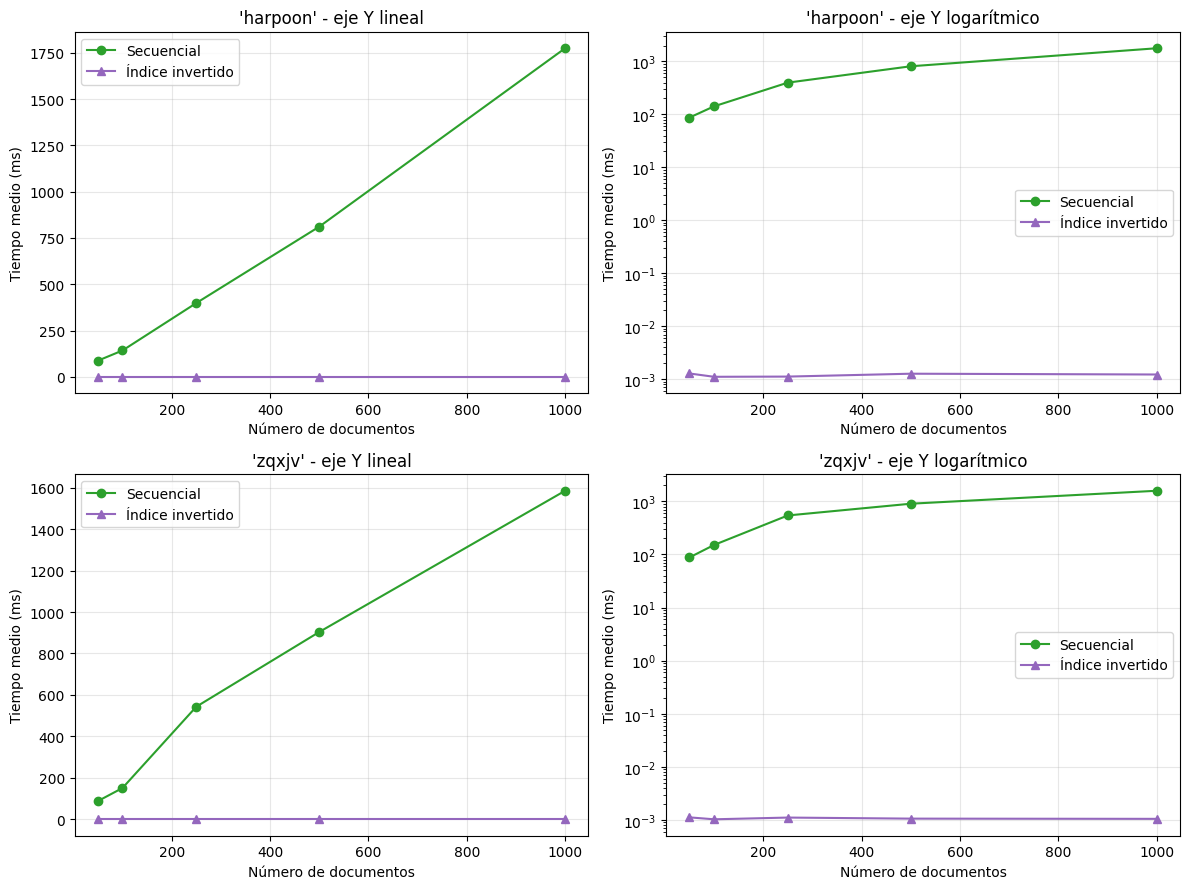

In [8]:
CONSULTAS_ESCALA = ["harpoon", "zqxjv"]

def tamano_mb(obj):
    return len(pickle.dumps(obj, protocol=pickle.HIGHEST_PROTOCOL)) / 1e6

def escalabilidad(tamanos, consultas, reps=REPS):
    filas = []
    for n in tamanos:
        sub = {i: corpus_grande[i] for i in ids_cargados[:n]}
        tokens = sum(len(v) for v in sub.values())

        ram_antes = ram_mb()
        t0 = time.perf_counter()
        idx = crear_indice(sub)
        t_indice = (time.perf_counter() - t0) * 1000
        ram_despues = ram_mb()
        mb_indice = tamano_mb(idx)

        for q in consultas:
            assert sorted(buscar_secuencial(q, sub)) == sorted(buscar_indice(q, idx))
            fila = {
                "n_docs": n, "consulta": q, "tokens": tokens,
                "seq_ms": tiempo_medio(buscar_secuencial, q, sub, veces=reps),
                "idx_ms": tiempo_medio(buscar_indice, q, idx, veces=reps),
                "vocabulario": len(idx),
                "crear_indice_ms": t_indice,
                "indice_MB": mb_indice,
                "RAM_indice_MB": ram_despues - ram_antes,
            }
            filas.append(fila)
            print(f"n={n} '{q}': secuencial {fila['seq_ms']:.3f} ms | índice {fila['idx_ms']:.5f} ms")
    return pd.DataFrame(filas)

resultados = escalabilidad(tamanos, CONSULTAS_ESCALA)
resultados.to_csv("resultados_escalabilidad.csv", index=False)
display(resultados)

fig, ejes = plt.subplots(len(CONSULTAS_ESCALA), 2, figsize=(12, 4.5 * len(CONSULTAS_ESCALA)), squeeze=False)
for fila, q in enumerate(CONSULTAS_ESCALA):
    d = resultados[resultados.consulta == q]
    for col, escala in enumerate(["linear", "log"]):
        ax = ejes[fila][col]
        ax.plot(d.n_docs, d.seq_ms, "o-", color="tab:green", label="Secuencial")
        ax.plot(d.n_docs, d.idx_ms, "^-", color="tab:purple", label="Índice invertido")
        ax.set_yscale(escala)
        ax.set_xlabel("Número de documentos")
        ax.set_ylabel("Tiempo medio (ms)")
        ax.set_title(f"'{q}' - eje Y {'lineal' if escala == 'linear' else 'logarítmico'}")
        ax.grid(alpha=.3)
        ax.legend()
plt.tight_layout()
plt.show()

**Interpretación.** La búsqueda secuencial pasa de ≈ 87 ms con 50 documentos a ≈ 1 585–1 775 ms con 1000, al crecer igual que el total de tokens de 3,1 M a 60,7 M. El índice se mantiene en ≈ 0,001 ms para todos los tamaños, por eso en la escala lineal queda pegado al eje X y se agregó la escala logarítmica. Construir el índice cuesta de 1,0 s (n = 50) a 6,4 s (n = 1000), y ocupa de 3,4 a 37,1 MB.

**9. Estimación de una función de tiempo**

Utilizando los resultados experimentales, determine una función:

$t=f(n)$

para cada método de recuperación.

Como primera aproximación, utilice un ajuste lineal por mínimos cuadrados:

$t(n)=an+b$

Estime los parámetros $a$ y $b$, reporte el coeficiente de determinación $R^2$ y represente las funciones ajustadas junto a los datos experimentales.

Explique si el modelo lineal representa adecuadamente las mediciones y cómo se relaciona con la complejidad computacional de cada algoritmo.

#### Ajuste lineal

,consulta,método,a (ms por doc),b (ms),R²
0,harpoon,Secuencial,1.786478e+00,-36.325963,0.997906
1,harpoon,Índice invertido,5.478165e-08,0.001185,0.066935
2,zqxjv,Secuencial,1.574300e+00,55.853345,0.986450
3,zqxjv,Índice invertido,-3.996683e-08,0.001089,0.157386


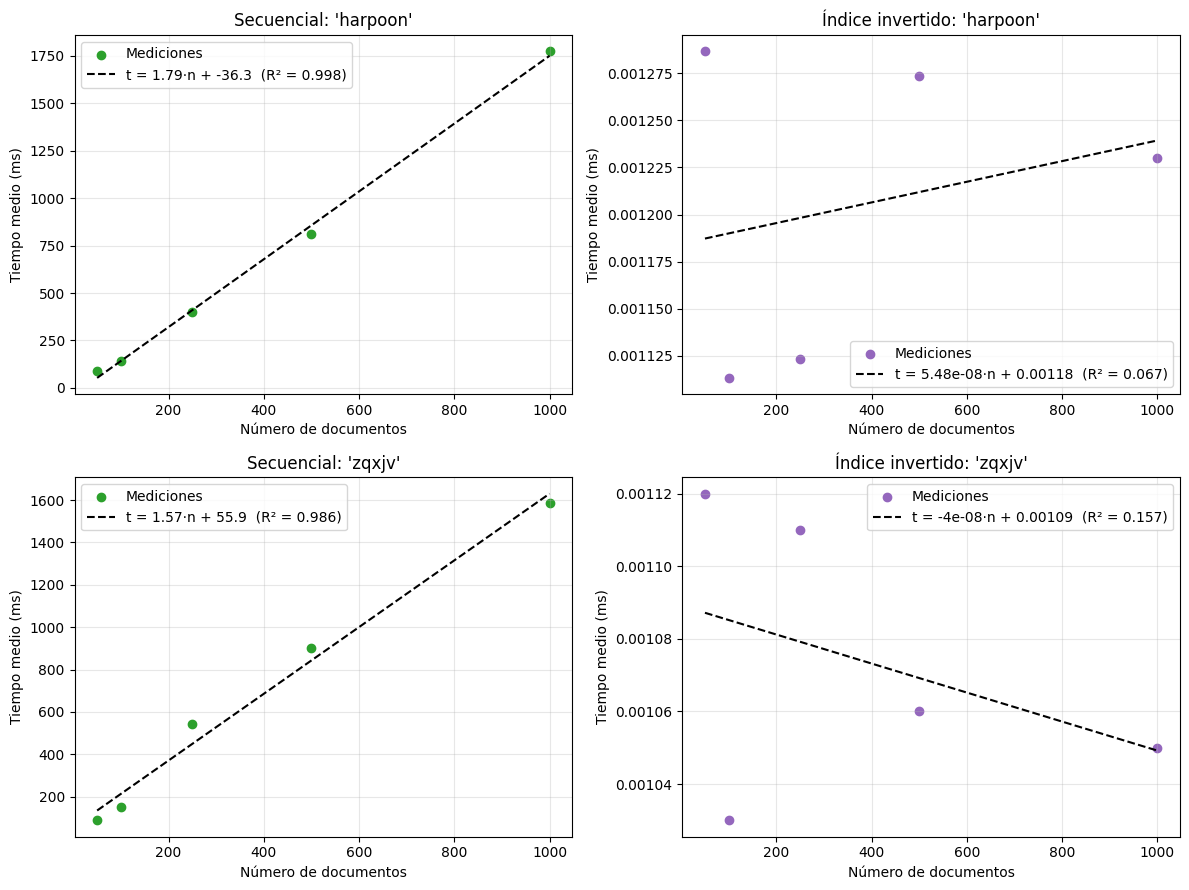

In [9]:
def minimos_cuadrados(x, y):
    x, y = np.array(x, dtype=float), np.array(y, dtype=float)
    a = np.sum((x - x.mean()) * (y - y.mean())) / np.sum((x - x.mean()) ** 2)
    b = y.mean() - a * x.mean()
    with np.errstate(invalid="ignore", divide="ignore"):
        r2 = np.corrcoef(x, y)[0, 1] ** 2
    return a, b, r2

filas, parametros = [], {}
for q in CONSULTAS_ESCALA:
    d = resultados[resultados.consulta == q]
    for metodo, col in [("Secuencial", "seq_ms"), ("Índice invertido", "idx_ms")]:
        a, b, r2 = minimos_cuadrados(d.n_docs, d[col])
        parametros[(q, metodo)] = (a, b, r2)
        filas.append({"consulta": q, "método": metodo, "a (ms por doc)": a, "b (ms)": b, "R²": r2})
display(pd.DataFrame(filas))

fig, ejes = plt.subplots(len(CONSULTAS_ESCALA), 2, figsize=(12, 4.5 * len(CONSULTAS_ESCALA)), squeeze=False)
for fila, q in enumerate(CONSULTAS_ESCALA):
    d = resultados[resultados.consulta == q]
    xs = np.linspace(d.n_docs.min(), d.n_docs.max(), 100)
    for col, (metodo, c, color) in enumerate([("Secuencial", "seq_ms", "tab:green"),
                                              ("Índice invertido", "idx_ms", "tab:purple")]):
        a, b, r2 = parametros[(q, metodo)]
        ax = ejes[fila][col]
        ax.scatter(d.n_docs, d[c], color=color, label="Mediciones")
        ax.plot(xs, a * xs + b, "--", color="black", label=f"t = {a:.3g}·n + {b:.3g}  (R² = {r2:.3f})")
        ax.set_xlabel("Número de documentos")
        ax.set_ylabel("Tiempo medio (ms)")
        ax.set_title(f"{metodo}: '{q}'")
        ax.grid(alpha=.3)
        ax.legend()
plt.tight_layout()
plt.show()

**Interpretación.** El modelo lineal representa bien a la búsqueda secuencial: los puntos quedan sobre la recta y el R² es 0,998 para `harpoon` y 0,986 para `zqxjv`. Tiene sentido, porque este método compara el término con cada token de cada documento, su costo es proporcional al total de tokens, O(T), y ese total crece más o menos de forma lineal con el número de documentos.

En el índice invertido, en cambio, la pendiente es prácticamente cero, porque consultar el índice es buscar una clave en un diccionario, que toma tiempo casi constante, O(1), sin importar cuántos documentos haya. Los tiempos son de microsegundos y se mezclan con el ruido de la medición, así que el R² sale bajo (0,067 y 0,157). 